In [64]:
#%pip install pyobis

In [1]:
import os
import pandas as pd
from tqdm import tqdm
import pyarrow as pa
import pyarrow.parquet as pq
import glob
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
from matplotlib_venn import venn3
from upsetplot import UpSet, from_memberships
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import re
import unicodedata
import requests
import geopandas as gpd
from shapely.geometry import Point
import xml.etree.ElementTree as ET
import dask.dataframe as dd
import csv
import chardet
import rasterio 
import geopandas as gpd
import numpy as np
from rasterio.transform import from_bounds
from osgeo import gdal
from fastparquet import ParquetFile
from datetime import datetime
import time
import pyobis

os.chdir ('C:\\Users\\Admin\\Documents\\arctic-benthic-biodiversity\\OBIS')

## Check column types

In [5]:
# Load the Parquet file
file_path = "merged_filtered.parquet"
df = pd.read_parquet(file_path)
# Display basic information about the dataset
print(f"Number of rows: {len(df)}")
print(f"Number of columns: {len(df.columns)}")
# Display column names and data types
print("Column names and data types:")
print(df.dtypes)
# Save column names and data types to a CSV file
output_csv = "column_data_types.csv"  # Specify the output CSV file name
column_info = pd.DataFrame({
    "Column Name": df.dtypes.index,  # Column names
    "Data Type": df.dtypes.values    # Corresponding data types
})
# Save the column information to a CSV file
column_info.to_csv(output_csv, index=False)
print(f"Column names and data types saved to {output_csv}")
# Calculate coverage (percentage of non-missing values) for each column
coverage = (df.notnull().sum() / len(df)) * 100  # Calculate percentage of non-missing values
coverage_df = pd.DataFrame({
    "Column Name": coverage.index,  # Column names
    "Coverage (%)": coverage.values  # Corresponding coverage percentages
})
# Display coverage information
print("Coverage (percentage of non-missing values) for each column:")
print(coverage_df)
# Save coverage information to a CSV file
coverage_csv = "column_coverage.csv"  # Specify the output CSV file name
coverage_df.to_csv(coverage_csv, index=False)
print(f"Coverage information saved to {coverage_csv}")

Number of rows: 619045
Number of columns: 227
Column names and data types:
basisOfRecord             object
brackish                  object
catalogNumber             object
class                     object
classid                  float64
                          ...   
roundedLongitude          object
unique_id                 object
associatedOccurrences     object
identifiedByID            object
vitality                  object
Length: 227, dtype: object
Column names and data types saved to column_data_types.csv
Coverage (percentage of non-missing values) for each column:
               Column Name  Coverage (%)
0            basisOfRecord    100.000000
1                 brackish     78.093515
2            catalogNumber     39.922461
3                    class     92.301852
4                  classid     92.301852
..                     ...           ...
222       roundedLongitude    100.000000
223              unique_id    100.000000
224  associatedOccurrences      0.053469
225  

# Data cleaning

## Filter out stations on land based on bathymetry

In [6]:
# Step 1: Load the Parquet file
input_file = "merged_filtered.parquet"
df = pd.read_parquet(input_file)
# Step 2: Extract unique station locations along with the year column
unique_stations = df[['decimalLatitude', 'decimalLongitude']].drop_duplicates()
# Step 3: Save the result to a new file
output_file = "unique_coordinates.parquet"
unique_stations.to_parquet(output_file, index=False)
# Optional: Save as CSV if needed
unique_stations.to_csv("unique_coordinates.csv", index=False)
print(f"Unique station locations with year saved to {output_file}")

Unique station locations with year saved to unique_coordinates.parquet


In [7]:
def extract_raster_values(raster_path, coordinates_df, batch_size=10000):
    """
    Extract raster values for given coordinates from a single raster file.
    Parameters:
        raster_path (str): Path to the merged raster file.
        coordinates_df (pd.DataFrame): DataFrame with 'decimalLatitude' and 'decimalLongitude'.
        batch_size (int): Number of points to process in each batch.
    Returns:
        pd.DataFrame: DataFrame with extracted raster values.
    """
    results = []
    total_batches = len(coordinates_df) // batch_size + (1 if len(coordinates_df) % batch_size != 0 else 0)
    with rasterio.open(raster_path) as src:
        bounds = src.bounds  # Get raster bounds
        with tqdm(total=total_batches, desc="Processing Batches", unit="batch") as pbar:
            for i in range(0, len(coordinates_df), batch_size):
                batch = coordinates_df.iloc[i:i + batch_size].copy()
                batch.loc[:, 'gebco'] = np.nan  # Initialize the column for raster values
                # Adjust longitudes at the antimeridian
                batch['decimalLongitude'] = batch['decimalLongitude'].apply(
                    lambda lon: -180 if lon == 180 else lon
                )
                # Filter coordinates within the raster bounds
                batch_in_bounds = batch[
                    (batch['decimalLongitude'] >= bounds.left) &
                    (batch['decimalLongitude'] <= bounds.right) &
                    (batch['decimalLatitude'] >= bounds.bottom) &
                    (batch['decimalLatitude'] <= bounds.top)
                ]
                # Extract raster values for these coordinates
                coords = [(lon, lat) for lon, lat in zip(batch_in_bounds['decimalLongitude'], batch_in_bounds['decimalLatitude'])]
                values = list(src.sample(coords))
                # Assign values to the batch DataFrame
                for idx, value in zip(batch_in_bounds.index, values):
                    if value[0] is not None and not np.isnan(value[0]):
                        batch.loc[idx, 'gebco'] = value[0]
                results.append(batch)
                pbar.update(1)
    return pd.concat(results, ignore_index=True)
# File path to the merged raster
raster_file = r"..\GEBCO\gebco_merged.tif"
# Load the unique_coordinates.parquet file
coordinates = pd.read_parquet("unique_coordinates.parquet")
# Ensure decimalLongitude and decimalLatitude are numeric
coordinates['decimalLongitude'] = pd.to_numeric(coordinates['decimalLongitude'], errors='coerce')
coordinates['decimalLatitude'] = pd.to_numeric(coordinates['decimalLatitude'], errors='coerce')
# Drop rows with invalid (NaN) coordinates
coordinates = coordinates.dropna(subset=['decimalLongitude', 'decimalLatitude'])
# Extract raster values
result_df = extract_raster_values(raster_file, coordinates)
# Save the results to a Parquet file
result_df.to_parquet("gebco_values.parquet", index=False)
# Save the results to a CSV file
result_df.to_csv("gebco_values.csv", index=False)
print("Results saved as 'gebco_values.parquet' and 'gebco_values.csv'.")

2026-01-23 14:09:03 - rasterio._env - WARNING - CPLE_AppDefined in PROJ: proj_create_from_database: C:\Users\Admin\anaconda3\Library\share\proj\proj.db contains DATABASE.LAYOUT.VERSION.MINOR = 2 whereas a number >= 4 is expected. It comes from another PROJ installation.
Processing Batches: 100%|██████████| 5/5 [00:04<00:00,  1.05batch/s]


Results saved as 'gebco_values.parquet' and 'gebco_values.csv'.


## Apply filter (remove records above zero)

In [8]:
# Load the Parquet file
coordinates = pd.read_parquet("gebco_values.parquet")
# Filter out stations with 'gebco' values above zero
filtered_coordinates = coordinates[coordinates['gebco'] <= 0]
# Save the filtered DataFrame to a new Parquet file
filtered_coordinates.to_parquet("gebco_filtered.parquet", index=False)
# Save the filtered DataFrame to a new CSV file
filtered_coordinates.to_csv("gebco_filtered.csv", index=False)
print("Filtered results saved as 'gebco_filtered.parquet' and 'gebco_filtered.csv'.")

Filtered results saved as 'gebco_filtered.parquet' and 'gebco_filtered.csv'.


In [9]:
# File paths
filtered_coordinates_file = "gebco_filtered.parquet"
gbif_file = "merged_filtered.parquet"
output_file = "obis_filtered_dataset_marine.parquet"
# Load the filtered coordinates (from gebco_values_filtered.parquet)
filtered_coordinates = pd.read_parquet(filtered_coordinates_file)
# Extract unique coordinate pairs and their corresponding 'gebco' values
filtered_coords_with_gebco = filtered_coordinates[['decimalLongitude', 'decimalLatitude', 'gebco']]
# Convert to a set for fast filtering
filtered_coords_set = set(zip(filtered_coords_with_gebco['decimalLongitude'], filtered_coords_with_gebco['decimalLatitude']))
# Define a function to filter a chunk and add the 'gebcoDepth' column
def filter_and_add_gebco(chunk, coords_with_gebco):
    """
    Filter a chunk of the GBIF dataset and add the 'gebcoDepth' column.
    Parameters:
        chunk (pd.DataFrame): A chunk of the GBIF dataset.
        coords_with_gebco (pd.DataFrame): DataFrame with 'decimalLongitude', 'decimalLatitude', and 'gebco'.
    Returns:
        pd.DataFrame: The filtered chunk with the 'gebcoDepth' column added.
    """
    # Convert 'decimalLongitude' and 'decimalLatitude' to numeric (float64) in the chunk
    chunk['decimalLongitude'] = pd.to_numeric(chunk['decimalLongitude'], errors='coerce')
    chunk['decimalLatitude'] = pd.to_numeric(chunk['decimalLatitude'], errors='coerce')
    # Create a tuple of (longitude, latitude) for each row in the chunk
    chunk_coords = zip(chunk['decimalLongitude'], chunk['decimalLatitude'])
    # Filter rows where the coordinate pair is in the filtered set
    filtered_chunk = chunk[[coord in filtered_coords_set for coord in chunk_coords]]
    # Merge the filtered chunk with the 'gebco' values
    filtered_chunk = filtered_chunk.merge(
        coords_with_gebco,
        on=['decimalLongitude', 'decimalLatitude'],
        how='left'
    )
    # Rename the 'gebco' column to 'gebcoDepth'
    filtered_chunk.rename(columns={'gebco': 'gebcoDepth'}, inplace=True)
    return filtered_chunk
# Open the GBIF dataset using fastparquet
pf = ParquetFile(gbif_file)
# Initialize counters
total_records_before = 0
total_records_after = 0
# Process each row group
filtered_chunks = []
for chunk in pf.iter_row_groups():
    total_records_before += len(chunk)
    
    # Filter the chunk and add the 'gebcoDepth' column
    filtered_chunk = filter_and_add_gebco(chunk, filtered_coords_with_gebco)
    filtered_chunks.append(filtered_chunk)
    total_records_after += len(filtered_chunk)
# Concatenate all filtered chunks into a single DataFrame
filtered_gbif = pd.concat(filtered_chunks, ignore_index=True)
# Save the filtered dataset to a new Parquet file
filtered_gbif.to_parquet(output_file, index=False)
# Save the filtered dataset to a new CSV file (optional)
filtered_gbif.to_csv(output_file.replace(".parquet", ".csv"), index=False)
print(f"Total records in the original OBIS dataset: {total_records_before}")
print(f"Total records after filtering: {total_records_after}")
print(f"Filtered OBIS dataset with 'gebcoDepth' saved as '{output_file}' and '{output_file.replace('.parquet', '.csv')}'.")

Total records in the original OBIS dataset: 619045
Total records after filtering: 573461
Filtered OBIS dataset with 'gebcoDepth' saved as 'obis_filtered_dataset_marine.parquet' and 'obis_filtered_dataset_marine.csv'.


# Which phyla have records on phylum level? 

In [10]:
# Load the dataset
file_path = "obis_filtered_dataset_marine.parquet"
df = pd.read_parquet(file_path)
# List of aphiaID values (as integers)
phyla = [
    882, 51, 1065, 1806, 1267, 558, 146142, 1821, 1803, 799, 
    152391, 1276, 793, 1818, 101060, 101063, 101061, 1789
]
# Filter the dataset to include only the specified acceptedTaxonKey values
filtered_df = df[df['aphiaID'].isin(phyla)]
# Filter records where 'class' is missing (null or empty)
missing_class_df = filtered_df[filtered_df['class'].isna() | (filtered_df['class'] == '')]
# Group by 'acceptedTaxonKey' and count the number of records per key
taxon_key_counts = missing_class_df.groupby('aphiaID').size().reset_index(name='record_count')
# Sort by the number of records in descending order
taxon_key_counts = taxon_key_counts.sort_values(by='record_count', ascending=False)
# Print the result
print(taxon_key_counts)

    aphiaID  record_count
6      1267         11349
10     1806          4495
16   152391          4144
15   146142          1368
3       799           933
9      1803           511
4       882           424
1       558           375
0        51           323
2       793           126
11     1818           109
14   101063            14
8      1789            14
5      1065             8
13   101060             8
7      1276             6
12     1821             2


1267: Cnidaria, 152391: Nemertea, 1806: Echinodermata, 558: Porifera, 146142: Bryozoa, 799: Nematoda, 1803: Brachiopoda, 51: Mollusca, 882: Annelida, 793: Platyhelminthes, 1818: Hemichordata, 101063: Priapulida, 1789: Phoronida, 1821: Chordata, 1065: Arthropoda, 101060: Kinorhyncha, 1276: Tardigrada

## Filter out records on phylum level for Arthropoda

In [11]:
# Load the dataset
file_path = "obis_filtered_dataset_marine.parquet"
df = pd.read_parquet(file_path)
# Filter out rows where aphiaID is 54
filtered_df = df[df['aphiaID'] != 1065]
# Save the filtered DataFrame to a new file
filtered_file_path = "obis_filtered_dataset.parquet"
filtered_df.to_parquet(filtered_file_path, index=False)
print(f"Filtered dataset saved as '{filtered_file_path}'")
# Optional: Verify the filtering
print(f"Original dataset size: {len(df)}")
print(f"Filtered dataset size: {len(filtered_df)}")

Filtered dataset saved as 'obis_filtered_dataset.parquet'
Original dataset size: 573461
Filtered dataset size: 573453


## Filter out records on phylum level for Mollusca

In [12]:
# Load the dataset
file_path = "obis_filtered_dataset.parquet"
df = pd.read_parquet(file_path)
# Filter out rows where aphiaID is 54
filtered_df = df[df['aphiaID'] != 51]
# Save the filtered DataFrame to a new file
filtered_file_path = "obis_filtered_dataset.parquet"
filtered_df.to_parquet(filtered_file_path, index=False)
print(f"Filtered dataset saved as '{filtered_file_path}'")
# Optional: Verify the filtering
print(f"Original dataset size: {len(df)}")
print(f"Filtered dataset size: {len(filtered_df)}")

Filtered dataset saved as 'obis_filtered_dataset.parquet'
Original dataset size: 573453
Filtered dataset size: 573130


## Filter out records on phylum level for Cnidaria

In [13]:
# Load the dataset
file_path = "obis_filtered_dataset.parquet"
df = pd.read_parquet(file_path)
# Filter out rows where aphiaID is 54
filtered_df = df[df['aphiaID'] != 1267]
# Save the filtered DataFrame to a new file
filtered_file_path = "obis_filtered_dataset.parquet"
filtered_df.to_parquet(filtered_file_path, index=False)
print(f"Filtered dataset saved as '{filtered_file_path}'")
# Optional: Verify the filtering
print(f"Original dataset size: {len(df)}")
print(f"Filtered dataset size: {len(filtered_df)}")

Filtered dataset saved as 'obis_filtered_dataset.parquet'
Original dataset size: 573130
Filtered dataset size: 561781


## Filter out records on phylum level for Chordata

In [14]:
# Load the dataset
file_path = "obis_filtered_dataset.parquet"
df = pd.read_parquet(file_path)
# Filter out rows where aphiaID is 54
filtered_df = df[df['aphiaID'] != 1821]
# Save the filtered DataFrame to a new file
filtered_file_path = "obis_filtered_dataset.parquet"
filtered_df.to_parquet(filtered_file_path, index=False)
print(f"Filtered dataset saved as '{filtered_file_path}'")
# Optional: Verify the filtering
print(f"Original dataset size: {len(df)}")
print(f"Filtered dataset size: {len(filtered_df)}")

Filtered dataset saved as 'obis_filtered_dataset.parquet'
Original dataset size: 561781
Filtered dataset size: 561779


## Verify

In [15]:
# Load the dataset
file_path = "obis_filtered_dataset.parquet"
df = pd.read_parquet(file_path)
# List of aphiaID values (as integers)
phyla = [
    882, 51, 1065, 1806, 1267, 558, 146142, 1821, 1803, 799, 
    152391, 1276, 793, 1818, 101060, 101063, 101061, 1789
]
# Filter the dataset to include only the specified acceptedTaxonKey values
filtered_df = df[df['aphiaID'].isin(phyla)]
# Filter records where 'class' is missing (null or empty)
missing_class_df = filtered_df[filtered_df['class'].isna() | (filtered_df['class'] == '')]
# Group by 'acceptedTaxonKey' and count the number of records per key
taxon_key_counts = missing_class_df.groupby('aphiaID').size().reset_index(name='record_count')
# Sort by the number of records in descending order
taxon_key_counts = taxon_key_counts.sort_values(by='record_count', ascending=False)
# Print the result
print(taxon_key_counts)

    aphiaID  record_count
7      1806          4495
12   152391          4144
11   146142          1368
2       799           933
6      1803           511
3       882           424
0       558           375
1       793           126
8      1818           109
5      1789            14
10   101063            14
9    101060             8
4      1276             6


# Sanity checks

## Check for duplicates

In [16]:
# Load the dataset
file_path = "obis_filtered_dataset.parquet"
df = pd.read_parquet(file_path)
# Find duplicate rows based on the 'id' column
duplicates = df[df.duplicated(subset='id', keep=False)]
# Count the number of duplicate rows
num_duplicates = len(duplicates)
# Sort the duplicates by 'id' (and optionally other columns)
duplicates_sorted = duplicates.sort_values(by='id')
# Optionally save the sorted duplicate rows to a CSV file for further inspection
duplicates_sorted.to_csv("duplicate_obis_records.csv", index=False)
# Print the number of duplicate rows and confirmation of saved file
print(f"Number of duplicate rows: {num_duplicates}")
print(f"Sorted duplicate records saved to 'duplicate_obis_records.csv'")

Number of duplicate rows: 0
Sorted duplicate records saved to 'duplicate_obis_records.csv'


## Coordinates

In [17]:
# Check latitude and longitude ranges
if "decimalLatitude" in df.columns and "decimalLongitude" in df.columns:
    print("Latitude and Longitude ranges:")
    print(f"Latitude: {df['decimalLatitude'].min()} to {df['decimalLatitude'].max()}")
    print(f"Longitude: {df['decimalLongitude'].min()} to {df['decimalLongitude'].max()}")

Latitude and Longitude ranges:
Latitude: 50.03 to 90.0
Longitude: -180.0 to 179.95425415


## Temporal coverage

In [18]:
# Check if the column exists in the DataFrame
if 'extractedEventYear' in df.columns:
    # Calculate the minimum and maximum values, ignoring NaN values
    min_year = df['extractedEventYear'].min()
    max_year = df['extractedEventYear'].max()
    
    # Print the results
    print(f"Minimum extractedEventYear: {min_year}")
    print(f"Maximum extractedEventYear: {max_year}")
else:
    print("Column 'extractedEventYear' does not exist in the DataFrame.")

Minimum extractedEventYear: 1858.0
Maximum extractedEventYear: 2025.0


## Unique values

In [19]:
# Load the Parquet file into a DataFrame
file_path = "obis_filtered_dataset.parquet"
df = pd.read_parquet(file_path)
# Calculate the number of unique entries in each column
unique_counts = df.nunique()
# Convert the results to a DataFrame
unique_counts_df = unique_counts.reset_index()
unique_counts_df.columns = ['Column', 'Unique_Count']
# Save the results to a CSV file
output_csv = "unique_counts_per_column.csv"
unique_counts_df.to_csv(output_csv, index=False)
print(f"Unique counts saved to {output_csv}")

Unique counts saved to unique_counts_per_column.csv


# Taxon counts

In [20]:
# Specify the categorical columns
categorical_columns = ["phylum", "class", "order", "family"]
# Loop through each column and save value counts as a CSV file
for col in categorical_columns:
    if col in df.columns:
        print(f"\nProcessing column: {col}")
        
        # Get value counts for the column
        value_counts = df[col].value_counts().reset_index()
        value_counts.columns = [col, "count"]  # Rename columns for clarity
        
        # Save to a CSV file
        output_file = f"record_counts_{col}.csv"
        value_counts.to_csv(output_file, index=False)
        
        print(f"Record counts for column '{col}' saved to {output_file}")


Processing column: phylum
Record counts for column 'phylum' saved to record_counts_phylum.csv

Processing column: class
Record counts for column 'class' saved to record_counts_class.csv

Processing column: order
Record counts for column 'order' saved to record_counts_order.csv

Processing column: family
Record counts for column 'family' saved to record_counts_family.csv


# Prepare for station-level filtering of P

## Group by station

In [27]:
# Load the Parquet file into a DataFrame
file_path = "obis_filtered_dataset.parquet"
df = pd.read_parquet(file_path)
# Group by the specified columns and count the number of rows for each unique combination
grouped = (
    df.groupby(['decimalLatitude', 'decimalLongitude', 'dataset_id'])
    .size()
    .reset_index(name='countPerStation')  # Add a 'count' column for the number of rows
)
# Optionally, save the result to a new file (e.g., CSV or Parquet)
grouped.to_csv("unique_stations.csv", index=False)

## Add date

In [47]:
# Load the CSV file
stations_file = "unique_stations.csv"
stations_df = pd.read_csv(stations_file)
# Load the Parquet file
parquet_file = "obis_filtered_dataset.parquet"
obis_df = pd.read_parquet(parquet_file)
# Check data types of the key columns
print("Stations DataFrame dtypes:")
print(stations_df[['decimalLatitude', 'decimalLongitude', 'dataset_id']].dtypes)
print("\nOBIS DataFrame dtypes:")
print(obis_df[['decimalLatitude', 'decimalLongitude', 'dataset_id']].dtypes)
# Convert data types to ensure consistency
stations_df['decimalLatitude'] = pd.to_numeric(stations_df['decimalLatitude'], errors='coerce')
stations_df['decimalLongitude'] = pd.to_numeric(stations_df['decimalLongitude'], errors='coerce')
stations_df['dataset_id'] = stations_df['dataset_id'].astype(str)
obis_df['decimalLatitude'] = pd.to_numeric(obis_df['decimalLatitude'], errors='coerce')
obis_df['decimalLongitude'] = pd.to_numeric(obis_df['decimalLongitude'], errors='coerce')
obis_df['dataset_id'] = obis_df['dataset_id'].astype(str)
# Select relevant columns and drop duplicates
obis_subset = obis_df[['decimalLatitude', 'decimalLongitude', 'dataset_id', 'year', 'extractedEventYear', 'samplingProtocol', 'bibliographicCitation']].drop_duplicates()
# Merge the two DataFrames on multiple keys
merged_df = pd.merge(
    stations_df,
    obis_subset,
    on=['decimalLatitude', 'decimalLongitude', 'dataset_id'],
    how='left'
)
# Remove duplicates to keep only unique station combinations
merged_df = merged_df.drop_duplicates(subset=['decimalLatitude', 'decimalLongitude', 'dataset_id'], keep='first')
# Save the merged DataFrame to a new CSV file
merged_df.to_csv("unique_stations_with_date.csv", index=False)

Stations DataFrame dtypes:
decimalLatitude     float64
decimalLongitude    float64
dataset_id           object
dtype: object

OBIS DataFrame dtypes:
decimalLatitude     float64
decimalLongitude    float64
dataset_id           object
dtype: object


# Visualize all stations

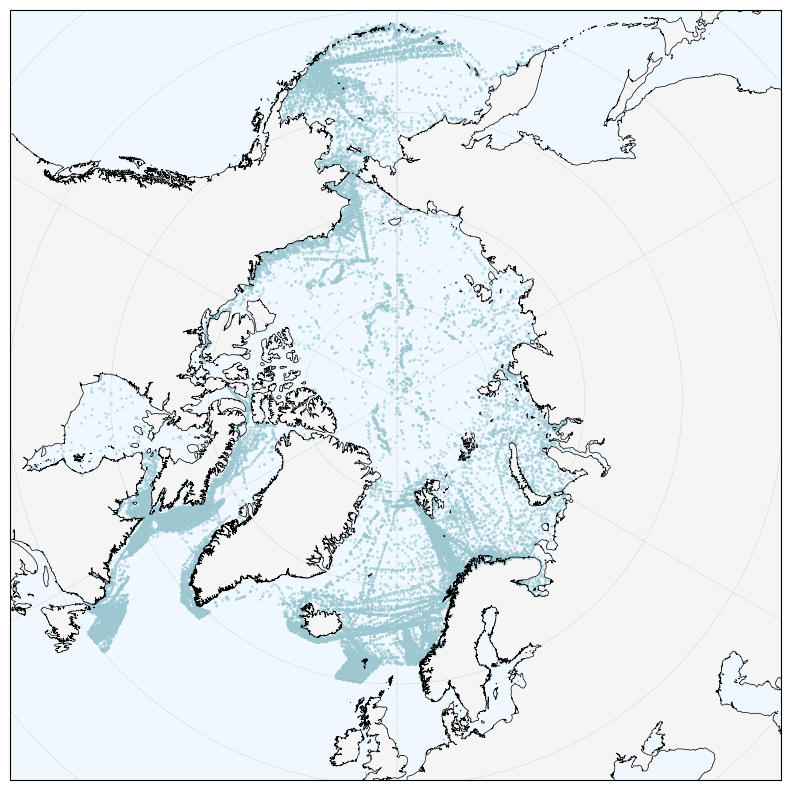

Plotted 61694 stations


In [48]:
# Load the dataset
file_path = "unique_stations_with_date.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['decimalLongitude', 'decimalLatitude']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['decimalLongitude'].values, coords['decimalLatitude'].values,
           s=1, color='#9DC8D2', alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

# Subset at station level

### Check that all station combinations have consistent 'keep' values

In [79]:
# Load the manual file
manual_df = pd.read_csv("unique_stations_with_status_manual.csv", low_memory=False)

# Group by the key columns and count unique 'keep' values per group
keep_check = manual_df.groupby(['decimalLatitude', 'decimalLongitude', 'dataset_id', 'samplingProtocol'])['keep'].nunique()

# Find groups with more than one unique 'keep' value
duplicates = keep_check[keep_check > 1]

if len(duplicates) > 0:
    print(f"⚠️ WARNING: Found {len(duplicates)} station combinations with multiple 'keep' values!")
    print("\nStation combinations with conflicting 'keep' values:")
    
    # Show the problematic stations with their different 'keep' values
    for idx in duplicates.index:
        lat, lon, dataset_id = idx
        station_data = manual_df[
            (manual_df['decimalLatitude'] == lat) & 
            (manual_df['decimalLongitude'] == lon) & 
            (manual_df['dataset_id'] == dataset_id)
        ]
        print(f"\nLat: {lat}, Lon: {lon}, Dataset: {dataset_id}")
        print(f"Keep values: {station_data['keep'].unique()}")
        print(station_data[['decimalLatitude', 'decimalLongitude', 'dataset_id', 'keep', 'bibliographicCitation']])
else:
    print(f"✓ All {len(keep_check)} station combinations have consistent 'keep' values.")

✓ All 29295 station combinations have consistent 'keep' values.


### Key in FUPR classification from manually edited file

In [99]:
# Merge station metadata with manual keep by full station keys
# Keys: decimalLatitude, decimalLongitude, dataset_id, samplingProtocol
# Strategy: Use rounded coordinates for matching (3 decimals ≈ 111m), preserve originals in output
csv_file = "unique_stations_with_date.csv"
manual_file = "unique_stations_with_status_manual.csv"
csv_data = pd.read_csv(csv_file)
manual_data = pd.read_csv(manual_file, low_memory=False)

# Normalize coordinates and dataset_id
for df_ in [csv_data, manual_data]:
    df_['decimalLatitude'] = pd.to_numeric(df_['decimalLatitude'], errors='coerce')
    df_['decimalLongitude'] = pd.to_numeric(df_['decimalLongitude'], errors='coerce')
    df_['dataset_id'] = df_['dataset_id'].astype(str).str.strip()

# Handle samplingProtocol separately and explicitly
csv_data['samplingProtocol'] = csv_data['samplingProtocol'].fillna('').astype(str).str.strip()
csv_data.loc[csv_data['samplingProtocol'] == 'nan', 'samplingProtocol'] = ''

manual_data['samplingProtocol'] = manual_data['samplingProtocol'].fillna('').astype(str).str.strip()
manual_data.loc[manual_data['samplingProtocol'] == 'nan', 'samplingProtocol'] = ''

# Create temporary rounded columns for matching (3 decimals ≈ 111m precision)
# Note: Original coordinates are preserved in output
csv_data['_lat_match'] = csv_data['decimalLatitude'].round(3)
csv_data['_lon_match'] = csv_data['decimalLongitude'].round(3)
manual_data['_lat_match'] = manual_data['decimalLatitude'].round(3)
manual_data['_lon_match'] = manual_data['decimalLongitude'].round(3)

# Ensure manual has one row per station key to avoid one-to-many expansion
match_keys = ['_lat_match', '_lon_match', 'dataset_id', 'samplingProtocol']
manual_keep = manual_data[match_keys + ['keep']].drop_duplicates(subset=match_keys)

# Merge on the rounded keys
merged_data = pd.merge(csv_data, manual_keep, on=match_keys, how='left')

# Drop temporary matching columns
merged_data = merged_data.drop(columns=['_lat_match', '_lon_match'])

output_file = "unique_stations_with_status.csv"
merged_data.to_csv(output_file, index=False)

# Report results
missing_count = merged_data['keep'].isna().sum()
print(f"Updated CSV saved as {output_file}")
print(f"Total rows: {len(merged_data)}")
print(f"Rows with keep: {len(merged_data) - missing_count}")
print(f"Rows missing keep: {missing_count}")

Updated CSV saved as unique_stations_with_status.csv
Total rows: 61694
Rows with keep: 61694
Rows missing keep: 0


In [100]:
# Load the dataset
file_path = "unique_stations_with_status.csv"
df = pd.read_csv(file_path)
# Filter rows where the 'keep' column is empty or null
missing_keep = df[df['keep'].isna() | (df['keep'] == '')]
# Count the number of rows with missing 'keep' values
missing_count = len(missing_keep)

# Check if there are any missing values
if missing_count > 0:
    print(f"⚠️ WARNING: {missing_count} stations have missing 'keep' values!")
    print("\nStations with missing 'keep' values:")
    print(unique_missing_keep[['dataset_id', 'bibliographicCitation']].to_string(index=False))
    raise ValueError(f"Execution stopped: {missing_count} stations are missing 'keep' values. Please review and update the data before continuing.")
else:
    print(f"✓ All stations have 'keep' values assigned. Total stations checked: {len(df)}")

✓ All stations have 'keep' values assigned. Total stations checked: 61694


##### If some stations lack keep values, add them manually and then save the file as unique_stations_with_status_manual.csv and rerun the part above

## Subset stations according to FUPR

In [101]:
# Load the updated CSV file
input_file = "unique_stations_with_status.csv"
data = pd.read_csv(input_file)
# Define the unique classes in the 'keep' column
classes = ['F', 'P', 'U', 'R']
# Loop through each class and create a subset
for cls in classes:
    subset = data[data['keep'] == cls]  # Filter rows where 'keep' equals the class
    output_file = f"unique_stations_with_status_{cls}.csv"  # Create a filename for the subset
    subset.to_csv(output_file, index=False)  # Save the subset to a new CSV file
    print(f"Saved subset for class '{cls}' as {output_file} with {len(subset)} stations.")
# Print the total count for each class
print("\nRecord counts per class:")
for cls in classes:
    count = len(data[data['keep'] == cls])
    print(f"Class '{cls}': {count} stations")

Saved subset for class 'F' as unique_stations_with_status_F.csv with 13135 stations.
Saved subset for class 'P' as unique_stations_with_status_P.csv with 6915 stations.
Saved subset for class 'U' as unique_stations_with_status_U.csv with 8 stations.
Saved subset for class 'R' as unique_stations_with_status_R.csv with 41636 stations.

Record counts per class:
Class 'F': 13135 stations
Class 'P': 6915 stations
Class 'U': 8 stations
Class 'R': 41636 stations


## Visualize subset coverage

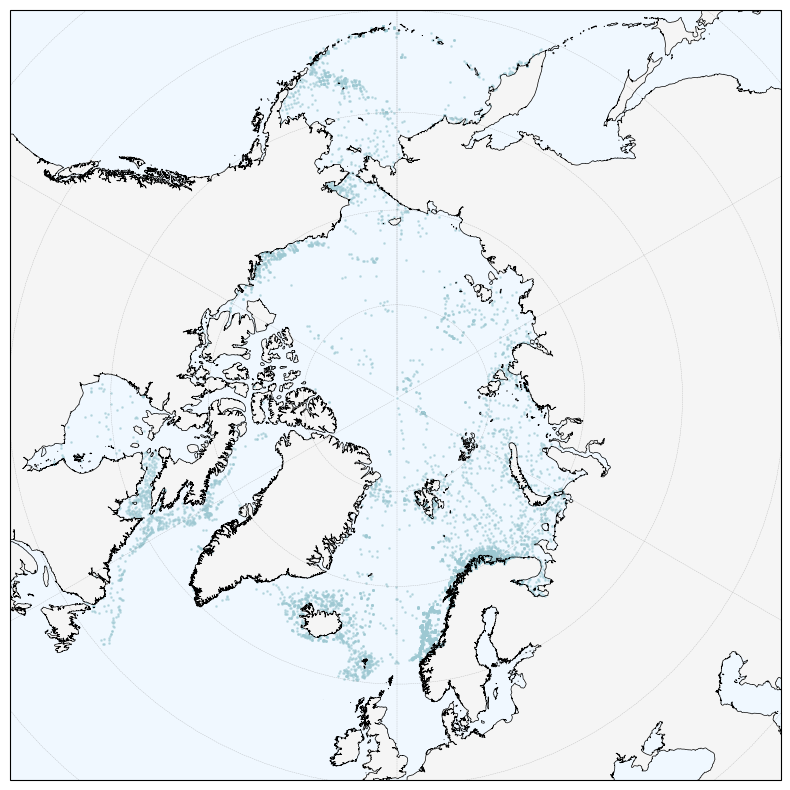

Plotted 13135 stations


In [102]:
# Load the dataset
file_path = "unique_stations_with_status_F.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['decimalLongitude', 'decimalLatitude']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['decimalLongitude'].values, coords['decimalLatitude'].values,
           s=1, color='#9DC8D2', alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

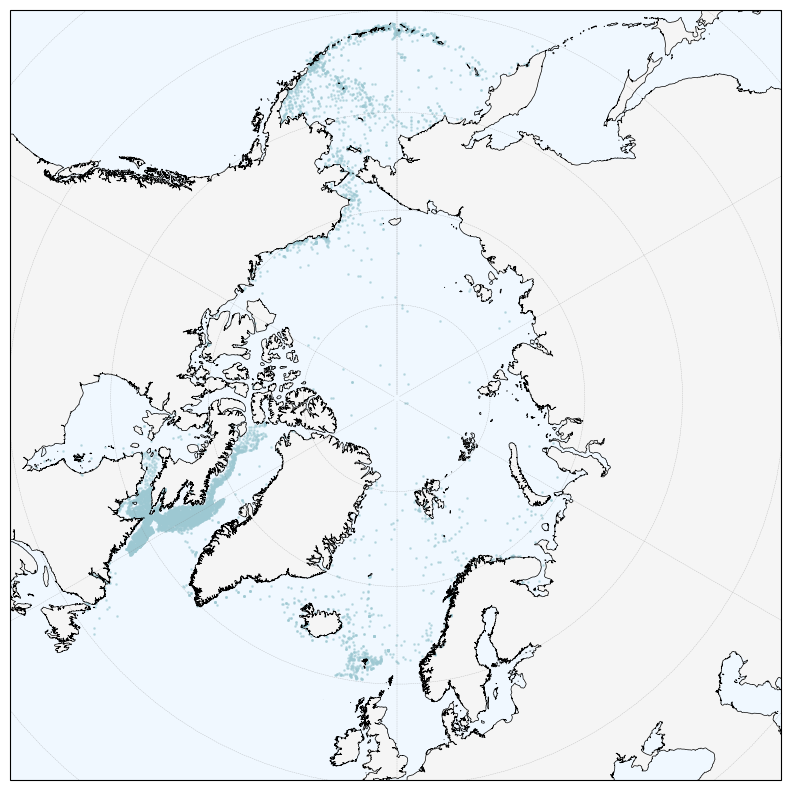

Plotted 6915 stations


In [103]:
# Load the dataset
file_path = "unique_stations_with_status_P.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['decimalLongitude', 'decimalLatitude']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['decimalLongitude'].values, coords['decimalLatitude'].values,
           s=1, color='#9DC8D2', alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

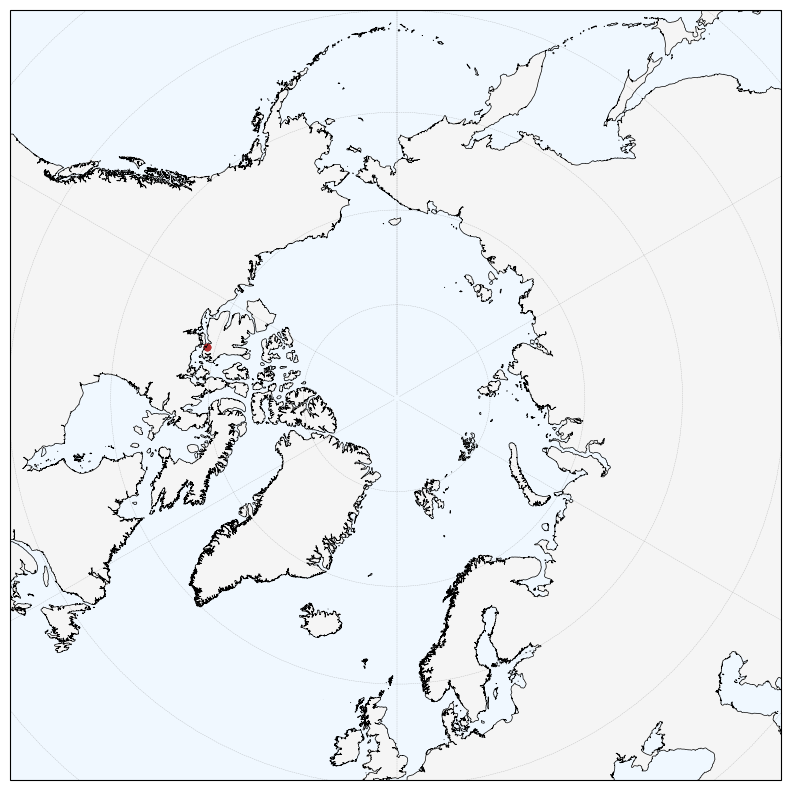

Plotted 8 stations


In [108]:
# Load the dataset
file_path = "unique_stations_with_status_U.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['decimalLongitude', 'decimalLatitude']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['decimalLongitude'].values, coords['decimalLatitude'].values,
           s=20, color="#B12E2E", alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

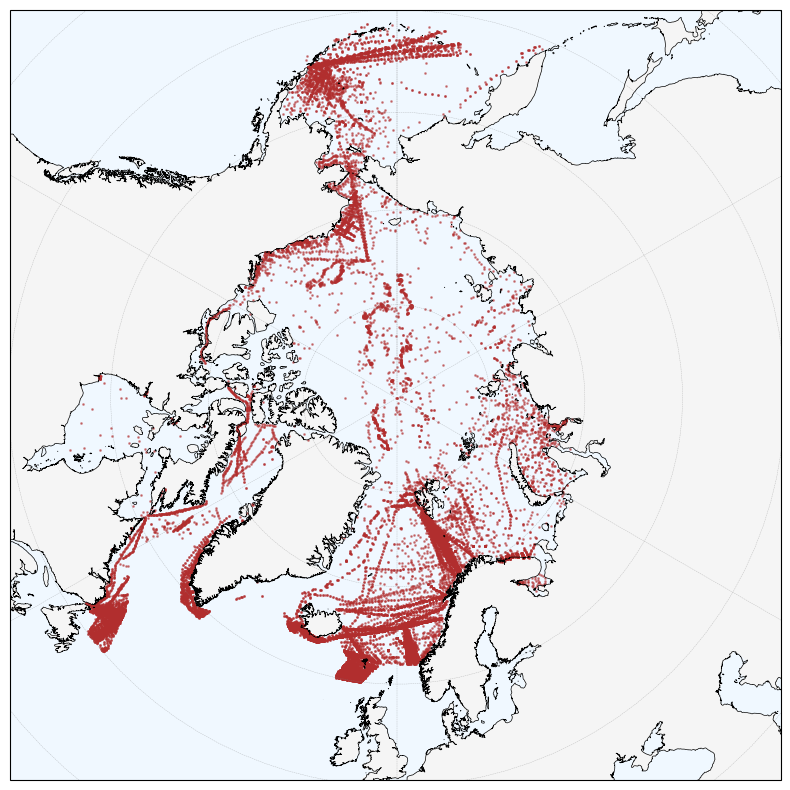

Plotted 41636 stations


In [110]:
# Load the dataset
file_path = "unique_stations_with_status_R.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['decimalLongitude', 'decimalLatitude']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['decimalLongitude'].values, coords['decimalLatitude'].values,
           s=1, color="#B12E2E", alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

# Subset at records level

In [111]:
# Load records and station-level keep classifications
records = pd.read_parquet("obis_filtered_dataset.parquet")
status = pd.read_csv("unique_stations_with_status.csv", low_memory=False)

# Normalize fields for matching
for df_ in (records, status):
    df_["decimalLatitude"] = pd.to_numeric(df_["decimalLatitude"], errors="coerce")
    df_["decimalLongitude"] = pd.to_numeric(df_["decimalLongitude"], errors="coerce")
    df_["dataset_id"] = df_["dataset_id"].astype(str).str.strip()
    df_["samplingProtocol"] = df_["samplingProtocol"].fillna("").astype(str).str.strip()
    df_.loc[df_["samplingProtocol"] == "nan", "samplingProtocol"] = ""
    df_["_lat_match"] = df_["decimalLatitude"].round(3)
    df_["_lon_match"] = df_["decimalLongitude"].round(3)

# Primary merge on rounded coords + dataset_id + samplingProtocol
primary_keys = ["_lat_match", "_lon_match", "dataset_id", "samplingProtocol"]
status_primary = status[primary_keys + ["keep"]].drop_duplicates(primary_keys)
merged = records.merge(status_primary, on=primary_keys, how="left")

# Secondary merge ignoring samplingProtocol for remaining unmatched
missing_mask = merged["keep"].isna() | (merged["keep"] == "")
if missing_mask.any():
    status_fallback = status[["_lat_match", "_lon_match", "dataset_id", "keep"]].drop_duplicates(
        ["_lat_match", "_lon_match", "dataset_id"]
    )
    fallback = (
        merged.loc[missing_mask, ["_lat_match", "_lon_match", "dataset_id"]]
        .merge(status_fallback, on=["_lat_match", "_lon_match", "dataset_id"], how="left")
        .get("keep")
    )
    merged.loc[missing_mask, "keep"] = fallback.values

# Drop helper columns
merged = merged.drop(columns=["_lat_match", "_lon_match"])

# Split into subsets
subsets = {}
for tag in ["F", "R", "U", "P"]:
    subsets[tag] = merged[merged["keep"] == tag]
    subsets[tag].to_parquet(f"obis_subset_{tag}.parquet", index=False)

unmatched = merged[merged["keep"].isna() | (merged["keep"] == "")]
unmatched.to_parquet("obis_subset_unmatched.parquet", index=False)

# Report counts
total = len(merged)
counts = {tag: len(df_) for tag, df_ in subsets.items()}
counts["unmatched"] = len(unmatched)

print(f"Total records: {total}")
for tag in ["F", "R", "U", "P", "unmatched"]:
    print(f"{tag}: {counts[tag]}")

if counts["unmatched"] > 0:
    print("⚠️ Warning: Some records remain unmatched. Please review 'obis_subset_unmatched.parquet'.")
else:
    print("✓ All records assigned to F/R/U/P; no unmatched records.")

Total records: 561779
F: 316070
R: 161191
U: 11748
P: 72770
unmatched: 0
✓ All records assigned to F/R/U/P; no unmatched records.


# Redistribute records based on taxa

### Obligate benthos

In [ ]:
# Load the subsets
subset_F = pd.read_parquet("obis_subset_F.parquet")
subset_P = pd.read_parquet("obis_subset_P.parquet")
# Define the conditions (keys are integers) (Sipuncula order instead of phylum here)
phylum_keys = [146142, 558, 1806, 1818, 101061, 101063, 152391, 799, 1803, 101060, 1276]
class_keys = [105, 104, 55, 1839, 101, 883, 2094, 1302, , 151365, 265044]
order_keys = [11713, 11718, 1454586, 1135, 1360, 1102, 1609357, 106033, 1362, 142028, 2854, 16236, 1137, 1268]
family_keys = [1614, 2039, 883967, 106738, 106782, 118264, 118280, 106737, 22805, 127500, 1594, 1608, 110380]
genus_keys = [798733, 117233, 136256, 117235, 118429, 146534]
# Function to clean and convert columns to Int64
def clean_and_convert_to_int64(column):
    # Replace invalid values (non-numeric or NaN) with pd.NA
    column = pd.to_numeric(column, errors='coerce')
    # Convert to nullable integer type (Int64)
    return column.astype('Int64')
# Clean and convert the key columns in subset_P
subset_P['phylumid'] = clean_and_convert_to_int64(subset_P['phylumid'])
subset_P['classid'] = clean_and_convert_to_int64(subset_P['classid'])
subset_P['orderid'] = clean_and_convert_to_int64(subset_P['orderid'])
subset_P['familyid'] = clean_and_convert_to_int64(subset_P['familyid'])
subset_P['genusid'] = clean_and_convert_to_int64(subset_P['genusid'])
# Filter records from subset_P that match the conditions, handling missing values with .notna()
records_to_move = subset_P[
    (subset_P['phylumid'].notna() & subset_P['phylumid'].isin(phylum_keys)) |
    (subset_P['classid'].notna() & subset_P['classid'].isin(class_keys)) |
    (subset_P['orderid'].notna() & subset_P['orderid'].isin(order_keys)) |
    (subset_P['familyid'].notna() & subset_P['familyid'].isin(family_keys)) |
    (subset_P['genusid'].notna() & subset_P['genusid'].isin(genus_keys))
]
# Count the number of records to move
num_records_moved = records_to_move.shape[0]
# Remove the filtered records from subset_P
subset_P = subset_P[~(
    (subset_P['phylumid'].notna() & subset_P['phylumid'].isin(phylum_keys)) |
    (subset_P['classid'].notna() & subset_P['classid'].isin(class_keys)) |
    (subset_P['orderid'].notna() & subset_P['orderid'].isin(order_keys)) |
    (subset_P['familyid'].notna() & subset_P['familyid'].isin(family_keys)) |
    (subset_P['genusid'].notna() & subset_P['genusid'].isin(genus_keys))
)]
# Add the filtered records to subset_F
subset_F = pd.concat([subset_F, records_to_move])
# Save the updated subsets back to Parquet files
subset_F.to_parquet("gbif_subset_F.parquet", index=False)
subset_P.to_parquet("gbif_subset_P.parquet", index=False)
# Print the number of records moved
print(f"Records moved successfully! Number of records moved: {num_records_moved}")